# Project work, part 3 - Data quality

GitHub Repository:
<https://github.com/sgkop/IND320-Innlevering-sgkop>

Streamlit App:
<https://ind320-innlevering1-sgkop.streamlit.app/>


## Setup

In [12]:
import pandas as pd
import numpy as np
import requests
import geopandas as gpd
import matplotlib.pyplot as plt

In [13]:
import requests

url = (
    "https://kart.nve.no/enterprise/rest/services/"
    "Mapservices/Administrasjon2/MapServer/0/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": True,
    "f": "json"
}

data = requests.get(
    url,
    params=params
).json()

In [14]:
for field in data["fields"]:
    print(field["name"])

Shape_Area
Shape_Length
OBJECTID
REGION
REGIONNAVN
POSTNUMMER
POSTSTED
BESØKSADR
ADRESSE


In [15]:
for feature in data["features"]:
    print(feature["attributes"]["REGION"])

RV
RM
RN
RØ
RS


In [16]:
regions_df = pd.DataFrame(
    [
        feature["attributes"]
        for feature in data["features"]
    ]
)

regions_df

,Shape_Area,Shape_Length,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESØKSADR,ADRESSE
0,7.541396e+10,1.673059e+06,1,RV,Region Vest,6801,Førde,Naustdalsveien 1B,Postboks 53
1,8.874660e+10,1.952347e+06,2,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9
2,1.675807e+11,2.886733e+06,3,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54
3,6.368011e+10,1.595783e+06,4,RØ,Region Øst,2307,Hamar,Vangsvegen 73,Postboks 4223
4,7.468574e+10,1.405013e+06,5,RS,Region Sør,3103,Tønsberg,Anton Jenssens gate 7,Postboks 2124


In [17]:
# Region overview
regions_df[
    ["REGION", "REGIONNAVN"]
]

,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


In [18]:
data["features"][0].keys()

dict_keys(['attributes', 'geometry'])

In [19]:
data["features"][0]["geometry"].keys()

dict_keys(['rings'])

In [20]:
len(data["features"][0]["geometry"]["rings"][0])

3123

In [21]:
# Create GeoDataFrame
from shapely.geometry import Polygon
import geopandas as gpd

records = []

for feature in data["features"]:

    attrs = feature["attributes"]

    polygon = Polygon(
        feature["geometry"]["rings"][0]
    )

    attrs["geometry"] = polygon

    records.append(attrs)

regions_gdf = gpd.GeoDataFrame(
    records,
    geometry="geometry",
    crs="EPSG:25833"
)

regions_gdf

,Shape_Area,Shape_Length,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESØKSADR,ADRESSE,geometry
0,7.541396e+10,1.673059e+06,1,RV,Region Vest,6801,Førde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,8.874660e+10,1.952347e+06,2,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,1.675807e+11,2.886733e+06,3,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,6.368011e+10,1.595783e+06,4,RØ,Region Øst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,7.468574e+10,1.405013e+06,5,RS,Region Sør,3103,Tønsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


In [22]:
regions_gdf[
    ["REGION", "REGIONNAVN"]
]

,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

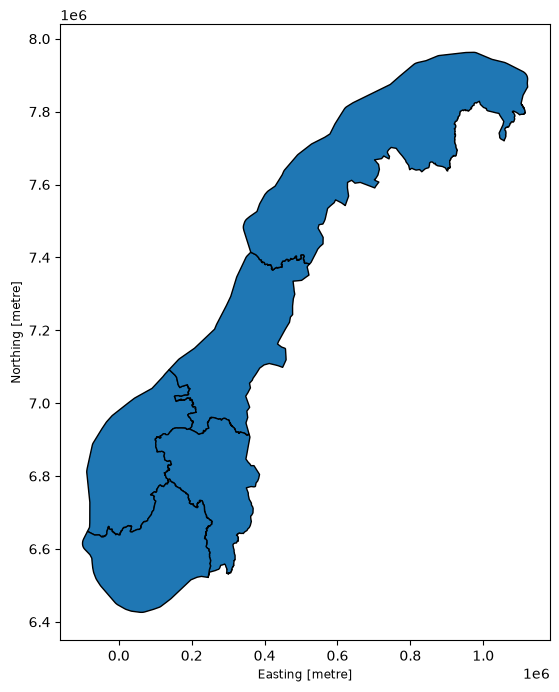

In [23]:
regions_gdf.plot(
    figsize=(8, 8),
    edgecolor="black"
)

In [24]:
# Random Sampling
import random
from shapely.geometry import Point

def sample_points(
    polygon,
    n=1000,
    seed=42
):

    random.seed(seed)

    minx, miny, maxx, maxy = polygon.bounds

    points = []

    while len(points) < n:

        point = Point(
            random.uniform(minx, maxx),
            random.uniform(miny, maxy)
        )

        if polygon.contains(point):
            points.append(point)

    return points

In [25]:
rm_polygon = regions_gdf.loc[
    regions_gdf["REGION"] == "RM",
    "geometry"
].iloc[0]

rm_points = sample_points(
    rm_polygon,
    n=1000
)

len(rm_points)

1000

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

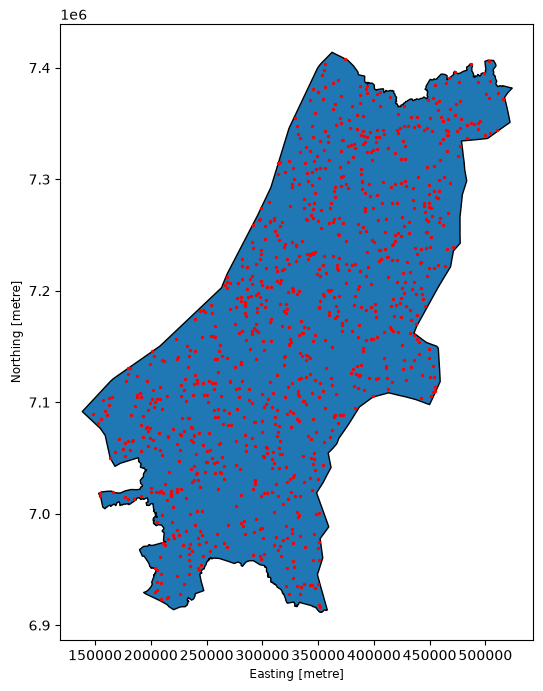

In [26]:
points_gdf = gpd.GeoDataFrame(
    geometry=rm_points,
    crs=regions_gdf.crs
)

ax = regions_gdf[
    regions_gdf["REGION"] == "RM"
].plot(
    figsize=(8,8),
    edgecolor="black"
)

points_gdf.plot(
    ax=ax,
    color="red",
    markersize=2
)


In [27]:
# Coordinate Conversion
points_gdf.head()

,geometry
0,POINT (244096.902 7024100.86)
1,POINT (422049.159 7251884.554)
2,POINT (388657.496 7185703.584)
3,POINT (448792.807 7262653.644)
4,POINT (269249.06 6990080.012)


In [28]:
points_wgs84 = points_gdf.to_crs(
    "EPSG:4326"
)

points_wgs84.head()

,geometry
0,POINT (9.89948 63.25427)
1,POINT (13.32294 65.38037)
2,POINT (12.65794 64.77738)
3,POINT (13.89408 65.48227)
4,POINT (10.44677 62.96695)


In [29]:
points_wgs84["longitude"] = (
    points_wgs84.geometry.x
)

points_wgs84["latitude"] = (
    points_wgs84.geometry.y
)

points_wgs84[
    ["latitude", "longitude"]
].head()

,latitude,longitude
0,63.254269,9.899484
1,65.380372,13.322943
2,64.777381,12.657935
3,65.482267,13.894083
4,62.966950,10.446766


In [30]:
sample_point = points_wgs84.iloc[0]

sample_point[
    ["latitude", "longitude"]
]

latitude     63.254269
longitude     9.899484
Name: 0, dtype: object

In [31]:
# Open-Meteo test
lat = sample_point["latitude"]
lon = sample_point["longitude"]

print(lat, lon)

63.25426937785838 9.899483754425445


In [32]:
url = (
    "https://archive-api.open-meteo.com/v1/archive"
)

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": [
        "temperature_2m",
        "precipitation"
    ]
}

response = requests.get(
    url,
    params=params
)

weather_data = response.json()

weather_data.keys()

dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

In [33]:
weather_data["hourly"].keys()

dict_keys(['time', 'temperature_2m', 'precipitation'])

In [34]:
weather_df = pd.DataFrame(
    weather_data["hourly"]
)

weather_df.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-6.4,0.0
1,2024-01-01T01:00,-6.3,0.0
2,2024-01-01T02:00,-6.4,0.0
3,2024-01-01T03:00,-6.4,0.0
4,2024-01-01T04:00,-6.4,0.0


In [35]:
# Weather Download Function
def download_weather(
    latitude,
    longitude,
    start_date,
    end_date
):

    url = (
        "https://archive-api.open-meteo.com/v1/archive"
    )

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "precipitation"
        ]
    }

    response = requests.get(
        url,
        params=params
    )

    data = response.json()

    return pd.DataFrame(
        data["hourly"]
    )

In [36]:
weather_df = download_weather(
    latitude=sample_point["latitude"],
    longitude=sample_point["longitude"],
    start_date="2024-01-01",
    end_date="2024-01-07"
)

weather_df.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-6.4,0.0
1,2024-01-01T01:00,-6.3,0.0
2,2024-01-01T02:00,-6.4,0.0
3,2024-01-01T03:00,-6.4,0.0
4,2024-01-01T04:00,-6.4,0.0


In [37]:
def get_region_points(
    region_code,
    n=1000
):

    polygon = regions_gdf.loc[
        regions_gdf["REGION"] == region_code,
        "geometry"
    ].iloc[0]

    points = sample_points(
        polygon,
        n=n
    )

    points_gdf = gpd.GeoDataFrame(
        geometry=points,
        crs=regions_gdf.crs
    )

    points_wgs84 = points_gdf.to_crs(
        "EPSG:4326"
    )

    points_wgs84["longitude"] = (
        points_wgs84.geometry.x
    )

    points_wgs84["latitude"] = (
        points_wgs84.geometry.y
    )

    return points_wgs84[
        ["latitude", "longitude"]
    ]

In [38]:
rm_points = get_region_points("RM")

rm_points.head()

,latitude,longitude
0,63.254269,9.899484
1,65.380372,13.322943
2,64.777381,12.657935
3,65.482267,13.894083
4,62.966950,10.446766


In [39]:
# Weather Download Function
def download_weather(
    latitude,
    longitude,
    start_date,
    end_date
):

    url = (
        "https://archive-api.open-meteo.com/v1/archive"
    )

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "precipitation"
        ]
    }

    response = requests.get(
        url,
        params=params
    )

    data = response.json()

    return pd.DataFrame(
        data["hourly"]
    )

In [40]:
weather_df = download_weather(
    latitude=rm_points.iloc[0]["latitude"],
    longitude=rm_points.iloc[0]["longitude"],
    start_date="2024-01-01",
    end_date="2024-01-07"
)

weather_df.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-6.4,0.0
1,2024-01-01T01:00,-6.3,0.0
2,2024-01-01T02:00,-6.4,0.0
3,2024-01-01T03:00,-6.4,0.0
4,2024-01-01T04:00,-6.4,0.0


In [41]:
def region_weather(
    region_code,
    start_date,
    end_date,
    n=1000
):

    points = get_region_points(
        region_code,
        n=n
    )

    sample_point = points.iloc[0]

    weather_df = download_weather(
        latitude=sample_point["latitude"],
        longitude=sample_point["longitude"],
        start_date=start_date,
        end_date=end_date
    )

    return weather_df

In [42]:
rm_weather = region_weather(
    region_code="RM",
    start_date="2024-01-01",
    end_date="2024-01-07"
)

rm_weather.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-6.4,0.0
1,2024-01-01T01:00,-6.3,0.0
2,2024-01-01T02:00,-6.4,0.0
3,2024-01-01T03:00,-6.4,0.0
4,2024-01-01T04:00,-6.4,0.0


In [43]:
# Download Weather Data for One Region
rm_points = get_region_points(
    "RM",
    n=10
)

rm_points.head()

,latitude,longitude
0,63.254269,9.899484
1,65.380372,13.322943
2,64.777381,12.657935
3,65.482267,13.894083
4,62.966950,10.446766


In [44]:
weather_1 = download_weather(
    latitude=rm_points.iloc[0]["latitude"],
    longitude=rm_points.iloc[0]["longitude"],
    start_date="2024-01-01",
    end_date="2024-01-31"
)

weather_2 = download_weather(
    latitude=rm_points.iloc[1]["latitude"],
    longitude=rm_points.iloc[1]["longitude"],
    start_date="2024-01-01",
    end_date="2024-01-31"
)

weather_3 = download_weather(
    latitude=rm_points.iloc[2]["latitude"],
    longitude=rm_points.iloc[2]["longitude"],
    start_date="2024-01-01",
    end_date="2024-01-31"
)

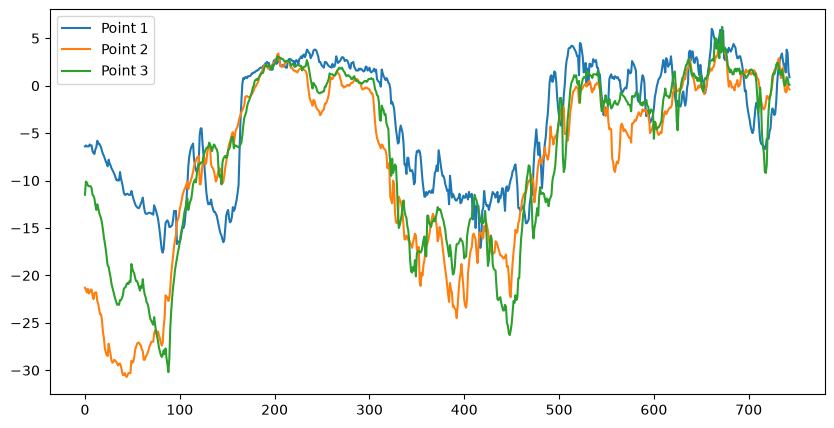

In [45]:
plt.figure(figsize=(10,5))

plt.plot(
    weather_1["temperature_2m"],
    label="Point 1"
)

plt.plot(
    weather_2["temperature_2m"],
    label="Point 2"
)

plt.plot(
    weather_3["temperature_2m"],
    label="Point 3"
)

plt.legend()

plt.show()

In [46]:
# Regional Weather Aggregation
def aggregate_region_weather(
    region_code,
    start_date,
    end_date,
    n_points=10
):

    points = get_region_points(
        region_code,
        n=n_points
    )

    all_weather = []

    for _, point in points.iterrows():

        weather_df = download_weather(
            latitude=point["latitude"],
            longitude=point["longitude"],
            start_date=start_date,
            end_date=end_date
        )

        all_weather.append(weather_df)

    return all_weather

In [47]:
weather_list = aggregate_region_weather(
    region_code="RM",
    start_date="2024-01-01",
    end_date="2024-01-07",
    n_points=3
)

len(weather_list)

3

In [48]:
weather_list[0].head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-6.4,0.0
1,2024-01-01T01:00,-6.3,0.0
2,2024-01-01T02:00,-6.4,0.0
3,2024-01-01T03:00,-6.4,0.0
4,2024-01-01T04:00,-6.4,0.0


In [49]:
regional_weather = weather_list[0].copy()

regional_weather["temperature_2m"] = (
    weather_list[0]["temperature_2m"]
    + weather_list[1]["temperature_2m"]
    + weather_list[2]["temperature_2m"]
) / 3

regional_weather["precipitation"] = (
    weather_list[0]["precipitation"]
    + weather_list[1]["precipitation"]
    + weather_list[2]["precipitation"]
) / 3

regional_weather.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-13.066667,0.0
1,2024-01-01T01:00,-12.633333,0.0
2,2024-01-01T02:00,-12.800000,0.0
3,2024-01-01T03:00,-12.766667,0.0
4,2024-01-01T04:00,-12.966667,0.0


In [50]:
def mean_weather(weather_list):

    regional_weather = weather_list[0].copy()

    regional_weather["temperature_2m"] = sum(
        df["temperature_2m"]
        for df in weather_list
    ) / len(weather_list)

    regional_weather["precipitation"] = sum(
        df["precipitation"]
        for df in weather_list
    ) / len(weather_list)

    return regional_weather

In [51]:
regional_weather = mean_weather(
    weather_list
)

regional_weather.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-13.066667,0.0
1,2024-01-01T01:00,-12.633333,0.0
2,2024-01-01T02:00,-12.800000,0.0
3,2024-01-01T03:00,-12.766667,0.0
4,2024-01-01T04:00,-12.966667,0.0


In [52]:
rm_weather = mean_weather(
    aggregate_region_weather(
        "RM",
        "2024-01-01",
        "2024-12-31",
        n_points=10
    )
)

In [53]:
rm_weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            8784 non-null   str    
 1   temperature_2m  8784 non-null   float64
 2   precipitation   8784 non-null   float64
dtypes: float64(2), str(1)
memory usage: 206.0 KB


In [54]:
rm_weather.head()

,time,temperature_2m,precipitation
0,2024-01-01T00:00,-11.18,0.0
1,2024-01-01T01:00,-10.74,0.0
2,2024-01-01T02:00,-10.89,0.0
3,2024-01-01T03:00,-10.93,0.0
4,2024-01-01T04:00,-10.88,0.0


In [55]:
# Analysis Settings

REGION_CODE = "RM"
YEAR = 2024

DEV_N_POINTS = 10

DCT_CUTOFF = 20
N_STD = 3

In [56]:
# Regional Weather Analysis
rm_weather["time"] = pd.to_datetime(
    rm_weather["time"]
)

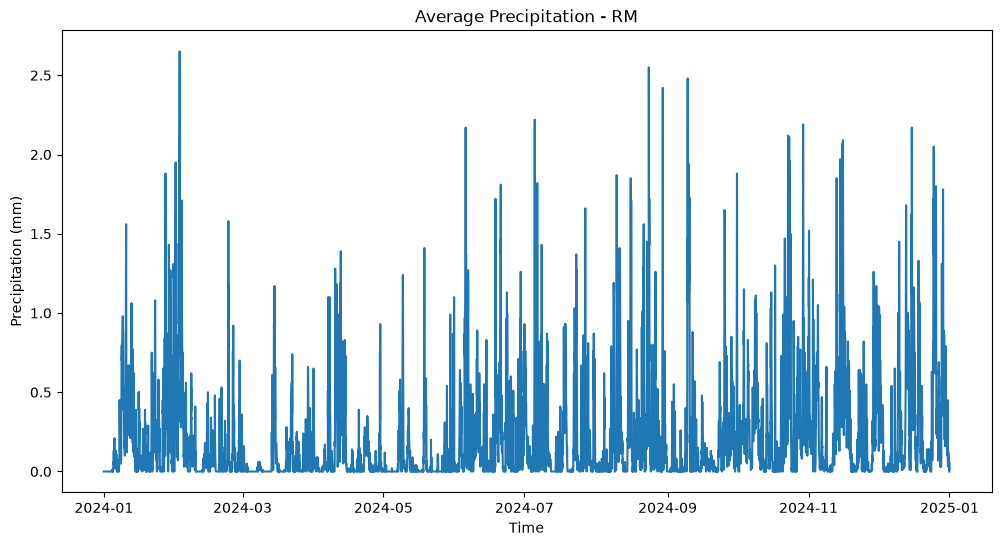

In [57]:
plt.figure(figsize=(12,6))

plt.plot(
    rm_weather["time"],
    rm_weather["precipitation"]
)

plt.title(
    "Average Precipitation - RM"
)

plt.xlabel("Time")
plt.ylabel("Precipitation (mm)")

plt.show()

In [58]:
# Daily Aggregation
daily_weather = (
    rm_weather
    .set_index("time")
    .resample("D")
    .agg({
        "temperature_2m": "mean",
        "precipitation": "sum"
    })
)

daily_weather.head()

,temperature_2m,precipitation
time,,
2024-01-01,-12.277500,0.00
2024-01-02,-17.686667,0.00
2024-01-03,-18.316250,0.00
2024-01-04,-18.036667,0.08
2024-01-05,-9.338333,2.18


In [59]:
daily_weather.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 366 entries, 2024-01-01 to 2024-12-31
Freq: D
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   temperature_2m  366 non-null    float64
 1   precipitation   366 non-null    float64
dtypes: float64(2)
memory usage: 8.6 KB


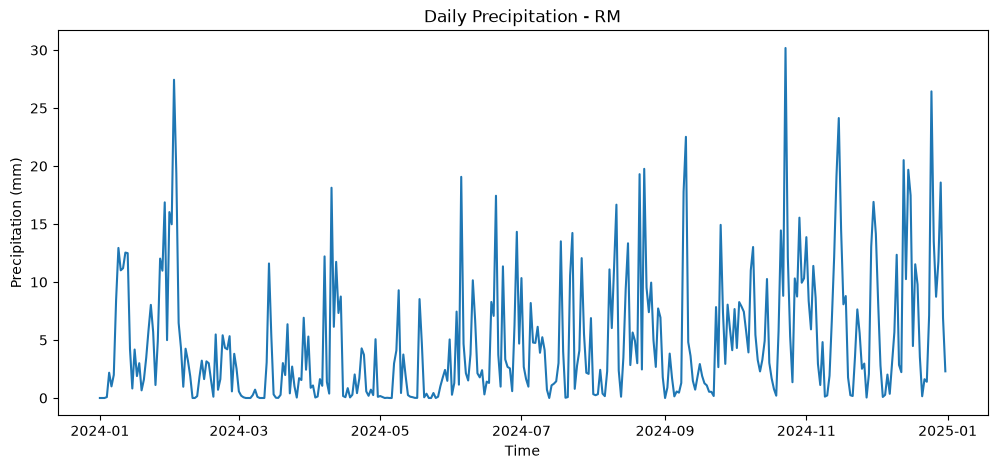

In [60]:
plt.figure(figsize=(12,5))

plt.plot(
    daily_weather.index,
    daily_weather["precipitation"]
)

plt.title(
    "Daily Precipitation - RM"
)

plt.xlabel("Time")
plt.ylabel("Precipitation (mm)")

plt.show()

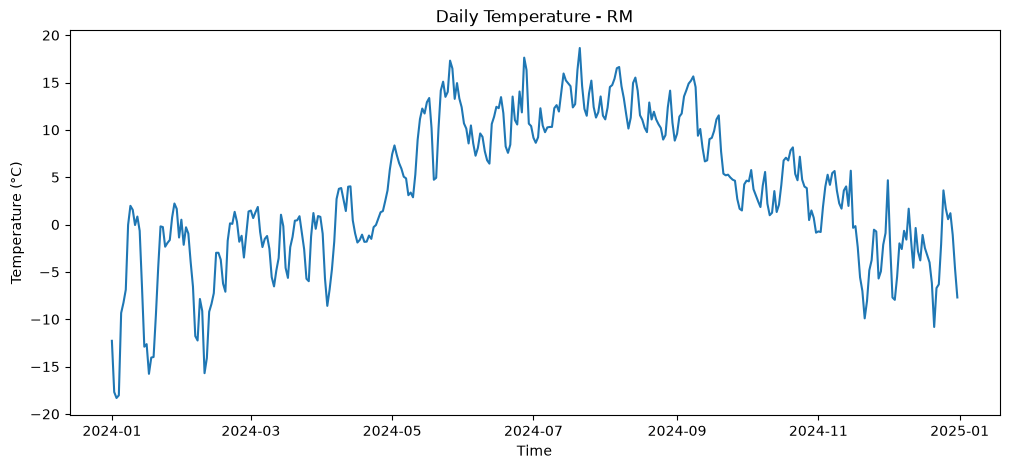

In [61]:
plt.figure(figsize=(12,5))

plt.plot(
    daily_weather.index,
    daily_weather["temperature_2m"]
)

plt.title(
    "Daily Temperature - RM"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.show()

# SPC and DCT Analysis

In [62]:
from scipy.fftpack import dct, idct

In [63]:
def precipitation_spc(
    precipitation_series,
    dct_cutoff=20,
    n_std=3
):

    signal = precipitation_series.values

    coeffs = dct(
        signal,
        norm="ortho"
    )

    filtered_coeffs = coeffs.copy()

    filtered_coeffs[:dct_cutoff] = 0

    satv = idct(
        filtered_coeffs,
        norm="ortho"
    )

    median = np.median(satv)

    mad = np.median(
        np.abs(satv - median)
    )

    robust_std = 1.4826 * mad

    upper_limit = (
        median
        + n_std * robust_std
    )

    lower_limit = (
        median
        - n_std * robust_std
    )

    outliers = (
        (satv > upper_limit)
        |
        (satv < lower_limit)
    )

    plt.figure(figsize=(12,5))

    plt.plot(
        precipitation_series.index,
        signal,
        label="Precipitation"
    )

    plt.axhline(
        upper_limit,
        color="red",
        linestyle="--",
        label="Upper SPC limit"
    )

    plt.axhline(
        lower_limit,
        color="red",
        linestyle="--",
        label="Lower SPC limit"
    )

    plt.scatter(
        precipitation_series.index[outliers],
        signal[outliers],
        color="orange",
        label="Outliers"
    )

    plt.legend()

    plt.title(
        "SPC Analysis of Precipitation"
    )

    plt.show()

    return {
        "n_outliers": outliers.sum(),
        "upper_limit": upper_limit,
        "lower_limit": lower_limit,
        "outliers": outliers
    }

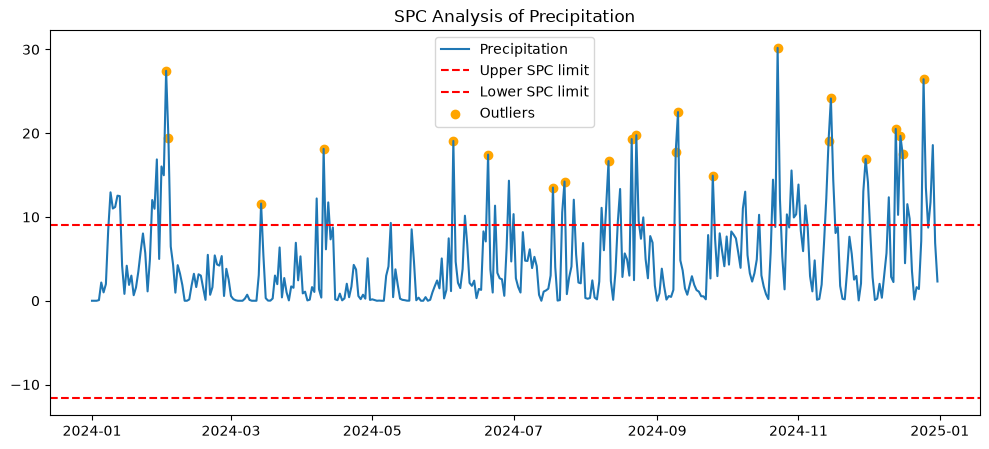

np.int64(22)

In [64]:
spc_results = precipitation_spc(
    daily_weather["precipitation"],
    dct_cutoff=DCT_CUTOFF,
    n_std=N_STD
)

spc_results["n_outliers"]

In [65]:
# LOF Analysis
from sklearn.neighbors import LocalOutlierFactor

In [66]:

def temperature_lof(
    temperature_series,
    contamination=0.01
):

    values = temperature_series.values.reshape(-1, 1)

    lof = LocalOutlierFactor(
        contamination=contamination
    )

    labels = lof.fit_predict(values)

    anomalies = labels == -1

    plt.figure(figsize=(12, 5))

    plt.plot(
        temperature_series.index,
        temperature_series.values,
        label="Temperature"
    )

    plt.scatter(
        temperature_series.index[anomalies],
        temperature_series.values[anomalies],
        color="red",
        label="Anomalies"
    )

    plt.title(
        "LOF Analysis of Temperature"
    )

    plt.legend()

    plt.show()

    return {
        "n_anomalies": anomalies.sum(),
        "anomalies": anomalies
    }

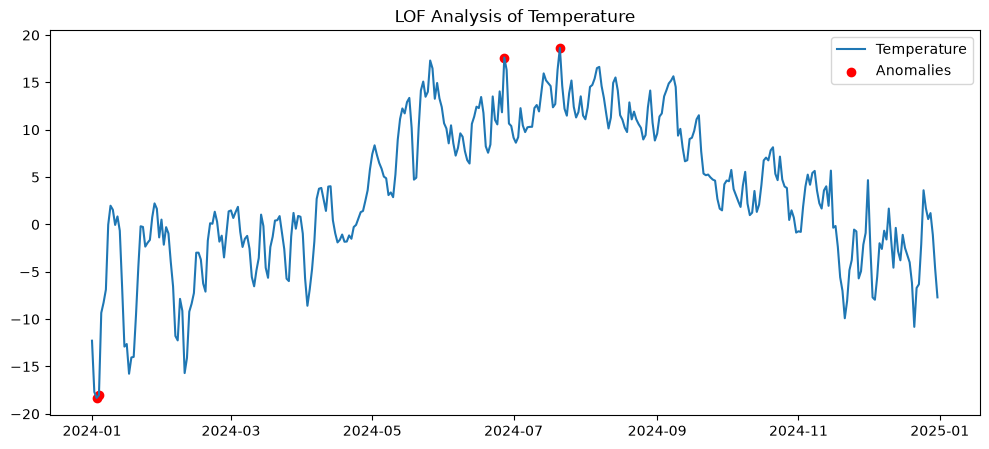

np.int64(4)

In [67]:
lof_results = temperature_lof(
    daily_weather["temperature_2m"],
    contamination=0.01
)

lof_results["n_anomalies"]

In [72]:
import requests
import pandas as pd

url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

response = requests.get(url)

magasin_data = response.json()

magasin_df = pd.DataFrame(
    magasin_data
)

In [75]:
filling_df = (
    magasin_df[
        (magasin_df["omrType"] == "EL")
        &
        (magasin_df["omrnr"] == 1)
    ]
    .copy()
)

filling_df["dato_Id"] = pd.to_datetime(
    filling_df["dato_Id"]
)

filling_df = filling_df.sort_values(
    "dato_Id"
)

filling_series = (
    filling_df
    .set_index("dato_Id")
    ["fyllingsgrad"]
)

In [76]:
filling_series.head()


dato_Id
1995-01-08    0.617574
1995-01-15    0.579205
1995-01-22    0.546713
1995-01-29    0.504545
1995-02-05    0.465335
Name: fyllingsgrad, dtype: float64

In [80]:
#STL Analysis
from statsmodels.tsa.seasonal import STL

In [83]:
def stl_analysis(
    series,
    seasonal=53,
    trend=105,
    robust=True
):

    stl = STL(
        series,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    fig = result.plot()

    plt.show()

    return result

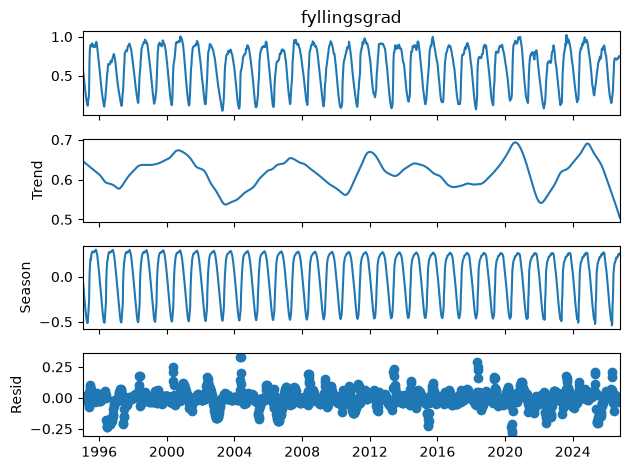

In [84]:
stl_result = stl_analysis(
    filling_series,
    seasonal=53,
    trend=105,
    robust=True
)

In [85]:
from scipy.signal import spectrogram

In [91]:
from scipy.signal import spectrogram
import numpy as np
import matplotlib.pyplot as plt


def spectrogram_analysis(
    series,
    window_length=128,
    overlap=64
):

    # Fjern gjennomsnittet
    series_centered = (
        series.values
        - np.mean(series.values)
    )

    frequencies, times, spectrum = spectrogram(
        series_centered,
        nperseg=window_length,
        noverlap=overlap
    )

    # Log-skala for bedre kontrast
    spectrum_db = 10 * np.log10(
        spectrum + 1e-12
    )

    plt.figure(figsize=(12, 5))

    plt.pcolormesh(
        times,
        frequencies,
        spectrum_db,
        shading="gouraud"
    )

    plt.ylabel("Frequency")
    plt.xlabel("Time")

    plt.title(
        "Spectrogram of Reservoir Filling"
    )

    plt.colorbar(
        label="Power (dB)"
    )

    plt.tight_layout()
    plt.show()

    return {
        "frequencies": frequencies,
        "times": times,
        "spectrum": spectrum
    }

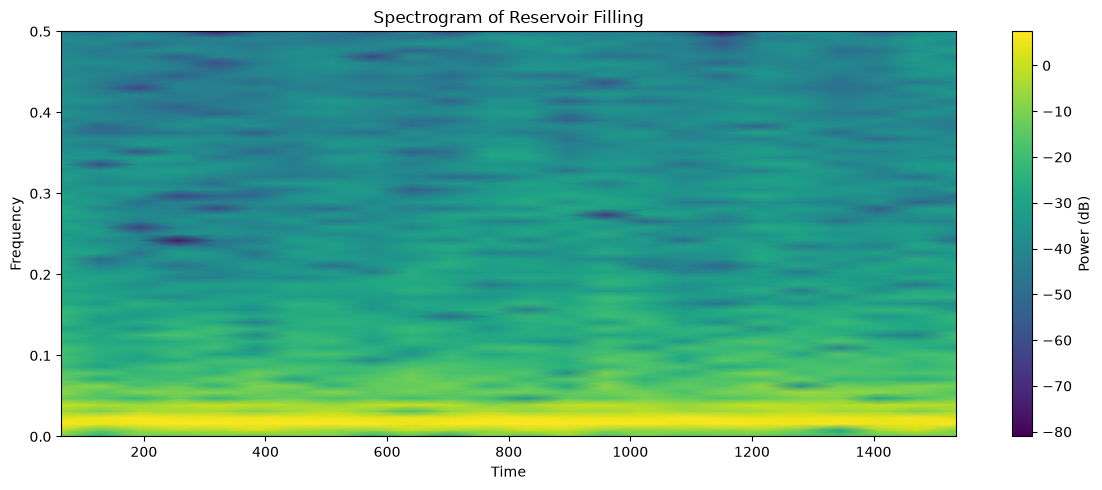

In [92]:
spectrogram_result = spectrogram_analysis(
    filling_series,
    window_length=128,
    overlap=64
)

## Log
The meteorological analysis was based on the NVE regional division (RV, RM, RN, RØ and RS) obtained from the NVE Atlas service. A reusable workflow was developed where weather data can be downloaded from a selected region and time interval. The implementation was demonstrated using Region Midt-Norge (RM), corresponding to the NO3 example specified in the assignment.

A deliberate development choice was to separate the reservoir and weather analyses. Reservoir analyses are based on degree-of-filling data from the Magasinstatistikk API, while weather analyses are based on Open-Meteo ERA5 reanalysis data. Because the datasets originate from different sources and represent different physical phenomena, they were presented as separate Streamlit pages with different analytical objectives.

For precipitation analysis, a Discrete Cosine Transform (DCT) was used to remove low-frequency seasonal variation before applying Statistical Process Control (SPC). Rather than using standard deviation, control limits were based on the Median Absolute Deviation (MAD). This choice was made because precipitation data contain occasional extreme events that can strongly influence traditional variance-based measures. The DCT frequency cut-off and the number of standard deviations were exposed as user-adjustable parameters.

Temperature anomalies were analysed using the Local Outlier Factor (LOF) method. LOF was selected because it identifies observations that are unusual relative to surrounding observations rather than relying on fixed thresholds. The contamination parameter was implemented as a configurable setting with a default value of 1%.

Reservoir filling data were analysed using Seasonal-Trend Decomposition using LOESS (STL) and a spectrogram. STL was chosen because it separates the filling series into trend, seasonal, and residual components, making long-term developments easier to interpret. Spectrogram analysis was included to investigate recurring frequency patterns in the same series. For both methods, the main tuning parameters were exposed to the user through the application.

All four analyses (SPC, LOF, STL and Spectrogram) were implemented as reusable functions, tested in the notebook, and then integrated into the Streamlit application. The application was extended with two dedicated analysis pages using tabbed navigation. Reservoir Analysis contains STL and Spectrogram analyses, while Weather Analysis contains SPC and LOF analyses. Explanatory text, summary statistics and configurable parameters were added to make the analytical choices visible and reproducible for the user

## AI usage
I acknowledge the use of M365 Copilot (https://www.microsoft.com/copilot), based on the GPT-5 chat model, during this project.

M365 Copilot was used to discuss project structure, evaluate alternative implementation choices, support debugging, explain analytical methods, and provide feedback on the development of both the Jupyter Notebook and the Streamlit application. In particular, Copilot was used to discuss data processing workflows, user-interface design decisions, implementation of SPC, LOF, STL and Spectrogram analyses, and the interpretation of assignment requirements.

M365 Copilot was also used to review, improve and refine written documentation, including the project log and explanatory text presented in the Streamlit application.

All code, visualisations, analysis choices and written content were reviewed, tested and adapted to reflect my own understanding, decisions and responsibility for the final submission.